In [4]:
import json
from pathlib import Path
from collections import defaultdict
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# Load annotations
TACO_PATH = Path("../data/TACO")
with open(TACO_PATH / "data/annotations.json") as f:
    taco = json.load(f)

# Basic stats
print("=" * 50)
print(f"  Total images:       {len(taco['images'])}")
print(f"  Total annotations:  {len(taco['annotations'])}")
print(f"  Total categories:   {len(taco['categories'])}")
print("=" * 50)

  Total images:       1500
  Total annotations:  4784
  Total categories:   60


In [5]:
# Count samples per category
cat_counts = defaultdict(int)
for ann in taco['annotations']:
    cat_counts[ann['category_id']] += 1

# Print sorted by sample count (descending)
print(f"{'ID':<5} {'Category Name':<40} {'Samples':<8}")
print("-" * 55)
for cat in sorted(taco['categories'], 
                  key=lambda x: cat_counts[x['id']], 
                  reverse=True):
    count = cat_counts[cat['id']]
    bar   = "█" * min(count // 5, 30)
    print(f"{cat['id']:<5} {cat['name']:<40} {count:<8} {bar}")

ID    Category Name                            Samples 
-------------------------------------------------------
59    Cigarette                                667      ██████████████████████████████
58    Unlabeled litter                         517      ██████████████████████████████
36    Plastic film                             451      ██████████████████████████████
5     Clear plastic bottle                     285      ██████████████████████████████
29    Other plastic                            273      ██████████████████████████████
39    Other plastic wrapper                    260      ██████████████████████████████
12    Drink can                                229      ██████████████████████████████
7     Plastic bottle cap                       209      ██████████████████████████████
55    Plastic straw                            157      ██████████████████████████████
9     Broken glass                             138      ███████████████████████████
57    Styrofoam piece

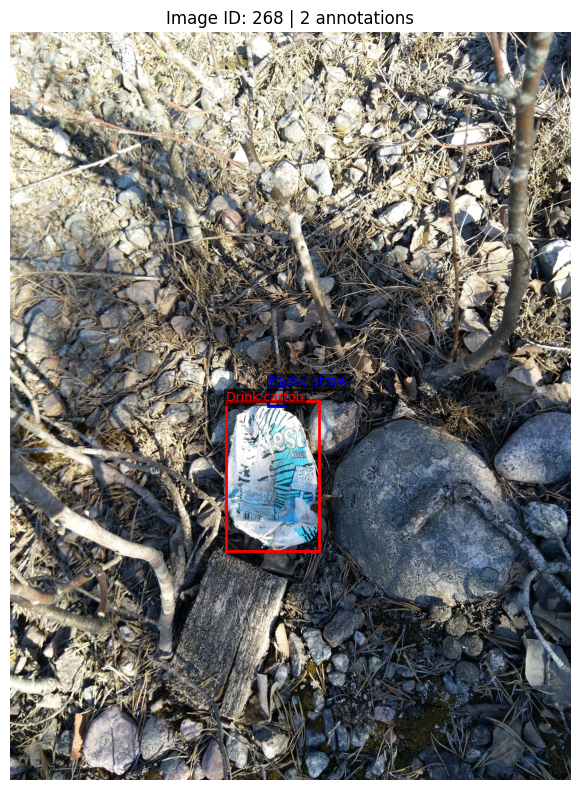

In [6]:
def show_sample(image_id=None):
    # Pick random image if none given
    import random
    img_info = next(
        i for i in taco['images'] 
        if i['id'] == (image_id or random.choice(taco['images'])['id'])
    )
    
    # Get its annotations
    anns = [a for a in taco['annotations'] 
            if a['image_id'] == img_info['id']]
    
    # Load image
    img_path = TACO_PATH /"data"/ img_info['file_name']
    img      = Image.open(img_path)
    
    fig, ax = plt.subplots(1, 1, figsize=(12, 8))
    ax.imshow(img)
    
    colors = ['red','blue','green','orange','purple','cyan','magenta','yellow']
    
    for i, ann in enumerate(anns):
        x, y, w, h = ann['bbox']
        cat_name    = next(c['name'] for c in taco['categories'] 
                           if c['id'] == ann['category_id'])
        color       = colors[i % len(colors)]
        rect        = patches.Rectangle(
                        (x, y), w, h,
                        linewidth=2, edgecolor=color, facecolor='none'
                      )
        ax.add_patch(rect)
        ax.text(x, y - 5, cat_name, color=color, fontsize=9,
                bbox=dict(facecolor='black', alpha=0.5, pad=1))
        
    ax.set_title(f"Image ID: {img_info['id']} | {len(anns)} annotations")
    ax.axis('off')
    plt.tight_layout()
    plt.show()

# Run it to see a random image from the dataset
show_sample()

In [5]:
print("⚠️  Categories with UNDER 30 samples (risky for training):")
print("-" * 50)
risky = []
for cat in taco['categories']:
    count = cat_counts[cat['id']]
    if count < 30:
        risky.append(cat['name'])
        print(f"  {cat['name']:<40} {count} samples")

print(f"\nTotal risky categories: {len(risky)}")
print("\n✅  Categories with 30+ samples (safe to use):")
for cat in taco['categories']:
    count = cat_counts[cat['id']]
    if count >= 30:
        print(f"  {cat['name']:<40} {count} samples")

⚠️  Categories with UNDER 30 samples (risky for training):
--------------------------------------------------
  Battery                                  2 samples
  Aluminium blister pack                   6 samples
  Carded blister pack                      1 samples
  Aerosol                                  10 samples
  Toilet tube                              5 samples
  Egg carton                               11 samples
  Pizza box                                3 samples
  Foam cup                                 13 samples
  Glass cup                                6 samples
  Other plastic cup                        2 samples
  Food waste                               8 samples
  Glass jar                                6 samples
  Metal lid                                10 samples
  Magazine paper                           12 samples
  Wrapping paper                           12 samples
  Paper bag                                27 samples
  Plastified paper bag             